<a class="anchor" id="1"></a>
# **K-Means Clustering : Unsupervised Learning Technique**

Today, we will explore **K-Means clustering**, one of the most popular unsupervised machine learning algorithms. We will start by understanding its core concepts using simple points, and then we will apply this exact same algorithm to a real world project: **Image Compression**.

### **1. Introduction**

#### **Supervised vs Unsupervised Learning**
Machine learning algorithms can be broadly classified into two categories:
*   **Supervised Learning:** We train the model with labeled data. For example, showing a model pictures of cats and dogs, and explicitly telling it "this is a cat" or "this is a dog".
*   **Unsupervised Learning:** The dataset has no labels. The model must find underlying structures, patterns, or groups on its own. **K-Means is an unsupervised learning algorithm.**

#### **What is Clustering?**
Clustering is the task of dividing a dataset into groups (called clusters) such that data points in the same group are more similar to each other than to those in other groups.

#### **Real-World Applications of Clustering**
1.  Customer segmentation (grouping customers by purchasing behavior)
2.   Document clustering (grouping news articles by topic)
3.   Anomaly detection (finding unusual data points)
4.  **Image segmentation and compression (what we will do today!)**

#### **Learning Objectives**
By the end of this notebook, you will understand:
1.  How the K-Means algorithm works.
2.  How to evaluate and choose the right number of clusters ($K$).
3.  The basic Machine Learning pipeline.



## K-Means

![K-Means](https://miro.medium.com/max/2160/1*tWaaZX75oumVwBMcKN-eHA.png)

<a class="anchor" id="2"></a>
# **2. Understand K-Means**

Let's understand how K-Means works intuitively before looking at complex data.

*   **What is K?** $K$ is the number of clusters we want to find in the data. We have to define this number before running the algorithm.
*   **What is a Centroid?** A centroid is a data point at the center of a cluster. It acts as the "representative" of all points assigned to that cluster.

### **The Algorithm Steps**
The K-Means algorithm is surprisingly simple and works iteratively:
1.  **Initialize:** Randomly place $K$ centroids in the data space.
2.  **Assign:** Calculate the distance between every data point and all $K$ centroids. Assign each point to its nearest centroid.
3.  **Update:** Calculate the new mean (center) of all points in each cluster, and move the centroid to this new position.
4.  **Repeat:** Repeat steps 2 and 3 until the centroids stop moving (this is called **convergence**).

Let's see this in action using a small, artificial 2D dataset!

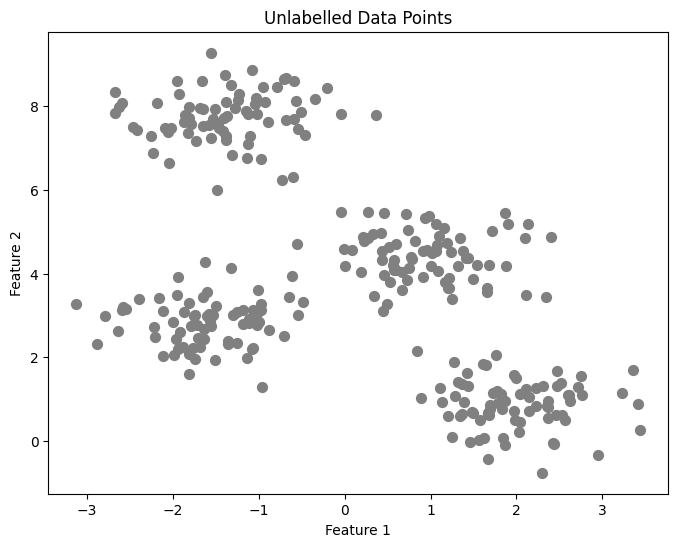

In [1]:
# Import basic libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

# Generate an artificial 2D dataset with 4 underlying groups
X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

# Plot the unlabelled data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50, color='gray')
plt.title("Unlabelled Data Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

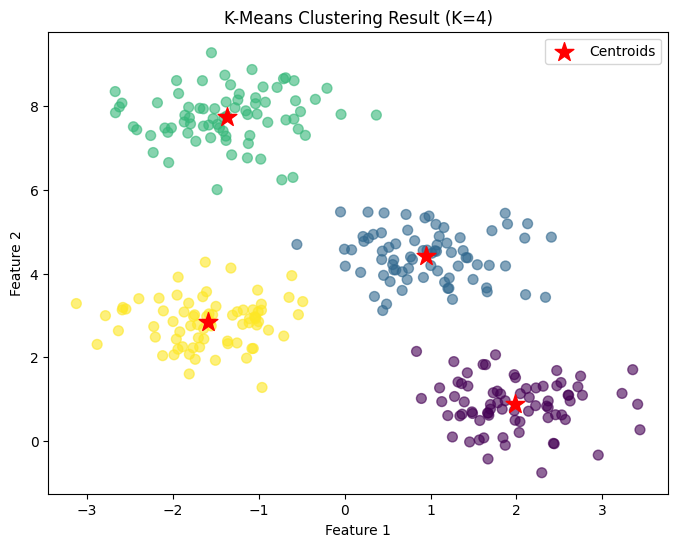

In [2]:
# Initialize K-Means with K=4
kmeans_2d = KMeans(n_clusters=4, random_state=42, n_init=10)

# Fit the model and assign labels
labels_2d = kmeans_2d.fit_predict(X)

# Get the final centroid coordinates
centroids_2d = kmeans_2d.cluster_centers_

# Plot the clustered data and centroids
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels_2d, s=50, cmap='viridis', alpha=0.6)
plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1], c='red', s=200, marker='*', label='Centroids')
plt.title("K-Means Clustering Result (K=4)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

# The Mathematics Behind K-Means Clustering


## Section 1 — What is K-Means?

In machine learning, we often have data without labels. Finding hidden structures in this data is called **unsupervised learning**.
**Clustering** is a specific type of unsupervised learning where the goal is to group similar data points together.

**K-Means** is an algorithm that tries to partition data into $K$ distinct clusters.
The main intuition behind K-Means is: **similar points should belong to the same cluster**, and we determine "similarity" based on how close the points are to each other in space.

Let's look at a simple 2D synthetic dataset.



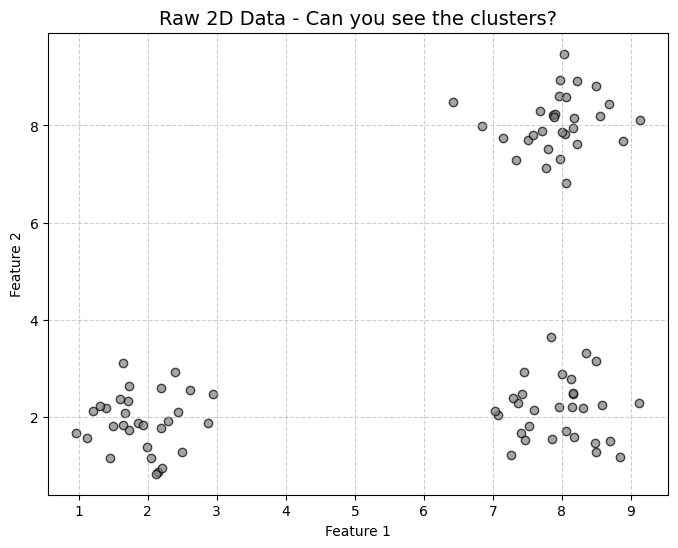

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility
np.random.seed(42)

# Generate a simple 2D synthetic dataset
cluster_1 = np.random.normal(loc=[2, 2], scale=0.6, size=(30, 2))
cluster_2 = np.random.normal(loc=[8, 8], scale=0.6, size=(30, 2))
cluster_3 = np.random.normal(loc=[8, 2], scale=0.6, size=(30, 2))
X_sample = np.vstack([cluster_1, cluster_2, cluster_3])

plt.figure(figsize=(8, 6))
plt.scatter(X_sample[:, 0], X_sample[:, 1], c='gray', alpha=0.7, edgecolors='k')
plt.title("Raw 2D Data - Can you see the clusters?", fontsize=14)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



---

## Section 2 — Representing Data Mathematically

Before writing any algorithm, we need to represent our data mathematically.

A single **data point** with $d$ features is represented as a vector:
$$ x_i = (x_{i1}, x_{i2}, ..., x_{id}) $$

- $i$ = index of the data point (e.g., 1st point, 2nd point)
- $d$ = number of features (dimensions)

Our entire **dataset** of $n$ points is a set:
$$ X = \{x_1, x_2, ..., x_n\} $$

K-Means relies on **centroids**. A centroid is the "center" of a cluster. It lives in the same $d$-dimensional space as our data points:
$$ \mu_k = (\mu_{k1}, \mu_{k2}, ..., \mu_{kd}) $$
where $k$ represents the $k$-th cluster.



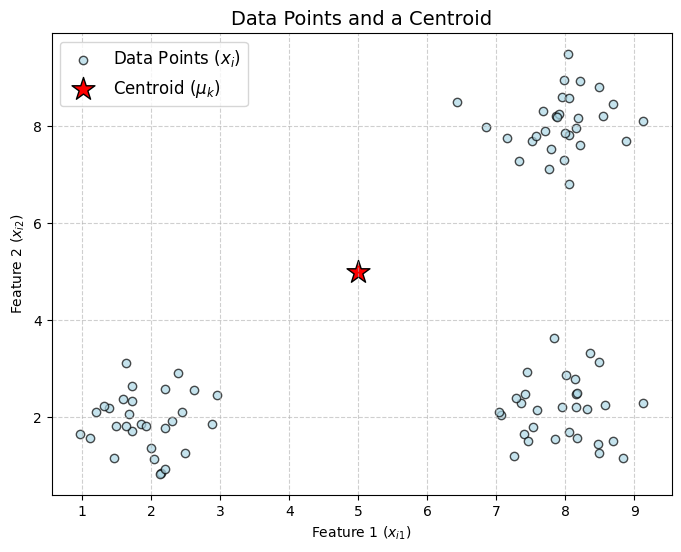

In [4]:
# Visualizing data points and a centroid
centroid_guess = np.array([5, 5])

plt.figure(figsize=(8, 6))
plt.scatter(X_sample[:, 0], X_sample[:, 1], c='lightblue', alpha=0.7, edgecolors='k', label='Data Points ($x_i$)')
plt.scatter(centroid_guess[0], centroid_guess[1], c='red', marker='*', s=300, edgecolor='k', label='Centroid ($\mu_k$)')

plt.title("Data Points and a Centroid", fontsize=14)
plt.xlabel("Feature 1 ($x_{i1}$)")
plt.ylabel("Feature 2 ($x_{i2}$)")
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



---

## Section 3 — Distance Mathematics

How do we measure if a point is "close" to a centroid? We use **Euclidean distance**.

For two points in a 2D space, $A=(x_1, y_1)$ and $B=(x_2, y_2)$, the distance is given by the Pythagorean theorem:
$$ d(A,B) = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2} $$

If our data has $d$ dimensions, we generalize this to the distance between a point $x$ and a centroid $\mu$:
$$ d(x,\mu) = \sqrt{\sum_{j=1}^{d}(x_j - \mu_j)^2} $$

In K-Means, we often use the **squared Euclidean distance**:
$$ d^2(x,\mu) = \sum_{j=1}^{d}(x_j - \mu_j)^2 $$

**Why squared distance?**
1. It removes the square root, making it computationally faster.
2. It mathematically penalizes points that are very far away.
3. The derivative of a squared function is linear and very easy to optimize (we will see this in Section 6).



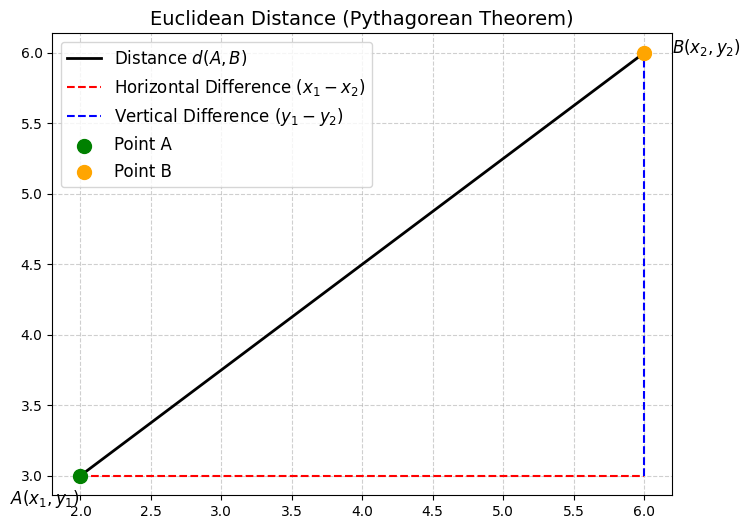

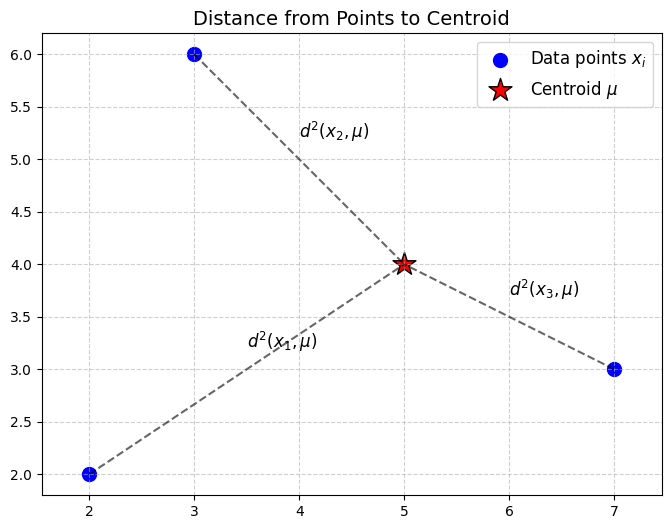

In [5]:
# Visualizing Euclidean Distance
A = np.array([2, 3])
B = np.array([6, 6])

plt.figure(figsize=(8, 6))
plt.plot([A[0], B[0]], [A[1], B[1]], 'k-', linewidth=2, label='Distance $d(A,B)$')
plt.plot([A[0], B[0]], [A[1], A[1]], 'r--', label='Horizontal Difference $(x_1 - x_2)$')
plt.plot([B[0], B[0]], [A[1], B[1]], 'b--', label='Vertical Difference $(y_1 - y_2)$')

plt.scatter(*A, c='green', s=100, zorder=5, label='Point A')
plt.scatter(*B, c='orange', s=100, zorder=5, label='Point B')

plt.text(A[0]-0.5, A[1]-0.2, "$A(x_1, y_1)$", fontsize=12)
plt.text(B[0]+0.2, B[1], "$B(x_2, y_2)$", fontsize=12)

plt.title("Euclidean Distance (Pythagorean Theorem)", fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axis('equal')
plt.show()

# Visualizing multiple distances to a centroid
plt.figure(figsize=(8, 6))
sample_points = np.array([[2, 2], [3, 6], [7, 3]])
mu = np.array([5, 4])

plt.scatter(sample_points[:, 0], sample_points[:, 1], c='blue', s=100, label='Data points $x_i$')
plt.scatter(mu[0], mu[1], c='red', marker='*', s=300, edgecolor='k', label='Centroid $\mu$')

for i, pt in enumerate(sample_points):
    plt.plot([pt[0], mu[0]], [pt[1], mu[1]], 'k--', alpha=0.6)
    plt.text((pt[0]+mu[0])/2, (pt[1]+mu[1])/2 + 0.2, f"$d^2(x_{i+1}, \mu)$", fontsize=12, color='black')

plt.title("Distance from Points to Centroid", fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axis('equal')
plt.show()



---

## Section 4 — Assignment Step

At the heart of K-Means is assigning each data point to its closest centroid.
Mathematically, a point $x_i$ is assigned to cluster $c_i$ according to:

$$ c_i = \arg\min_{k} \|x_i - \mu_k\|^2 $$

Let's break down these symbols:
- $c_i$: The cluster index assigned to data point $i$.
- $\arg\min_k$: "Find the value of $k$ that makes the following expression as small as possible."
- $\|x_i - \mu_k\|^2$: The squared Euclidean distance between point $x_i$ and centroid $\mu_k$.

In plain English: **"Calculate the squared distance from point $x_i$ to every centroid, and assign $x_i$ to the centroid that gives the smallest distance."**



Squared distance to mu_1: 8.00
Squared distance to mu_2: 17.00
Point x_i is assigned to cluster: 1


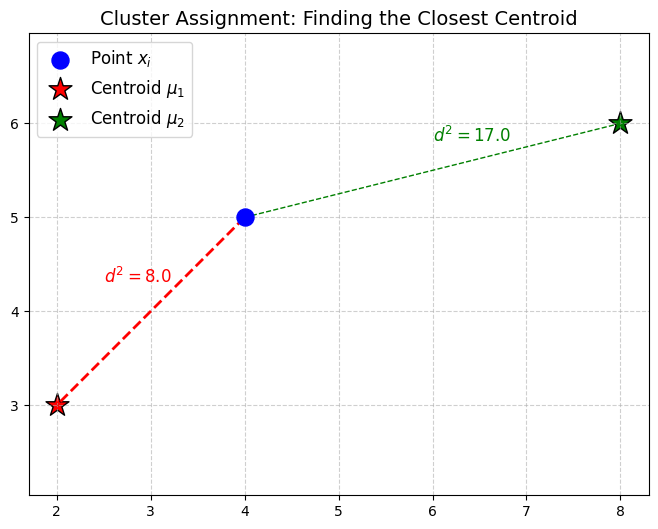

In [6]:
# Visualizing the Assignment Step
x_i = np.array([4, 5])
mu_1 = np.array([2, 3])
mu_2 = np.array([8, 6])

# Manual Distance Calculation in Python
dist_to_mu_1 = np.sum((x_i - mu_1)**2)
dist_to_mu_2 = np.sum((x_i - mu_2)**2)

closest_mu = 1 if dist_to_mu_1 < dist_to_mu_2 else 2

print(f"Squared distance to mu_1: {dist_to_mu_1:.2f}")
print(f"Squared distance to mu_2: {dist_to_mu_2:.2f}")
print(f"Point x_i is assigned to cluster: {closest_mu}")

plt.figure(figsize=(8, 6))
plt.scatter(*x_i, c='blue', s=150, zorder=5, label='Point $x_i$')
plt.scatter(*mu_1, c='red', marker='*', s=300, edgecolor='k', label='Centroid $\mu_1$')
plt.scatter(*mu_2, c='green', marker='*', s=300, edgecolor='k', label='Centroid $\mu_2$')

plt.plot([x_i[0], mu_1[0]], [x_i[1], mu_1[1]], 'r--', linewidth=2 if closest_mu==1 else 1)
plt.plot([x_i[0], mu_2[0]], [x_i[1], mu_2[1]], 'g--', linewidth=2 if closest_mu==2 else 1)

plt.text((x_i[0]+mu_1[0])/2 - 0.5, (x_i[1]+mu_1[1])/2 + 0.3, f"$d^2 = {dist_to_mu_1:.1f}$", color='red', fontsize=12)
plt.text((x_i[0]+mu_2[0])/2, (x_i[1]+mu_2[1])/2 + 0.3, f"$d^2 = {dist_to_mu_2:.1f}$", color='green', fontsize=12)

plt.title("Cluster Assignment: Finding the Closest Centroid", fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axis('equal')
plt.show()



---

## Section 5 — Centroid Mathematics

Once all points are assigned to clusters, we must update the position of the centroids.
The new centroid is simply the **mean** (average) of all points belonging to that cluster.

For 1-dimensional data:
$$ \mu = \frac{x_1 + x_2 + \cdots + x_n}{n} $$

For 2D data:
$$ \mu_x = \frac{1}{n}\sum_{i=1}^{n}x_{i,x} \quad \text{and} \quad \mu_y = \frac{1}{n}\sum_{i=1}^{n}x_{i,y} $$

The general form for updating centroid $\mu_k$ for cluster $C_k$ is:
$$ \boxed{ \mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i } $$

- $|C_k|$ is the number of points in cluster $k$.
- $\sum_{x_i \in C_k} x_i$ is the vector sum of all points assigned to cluster $k$.



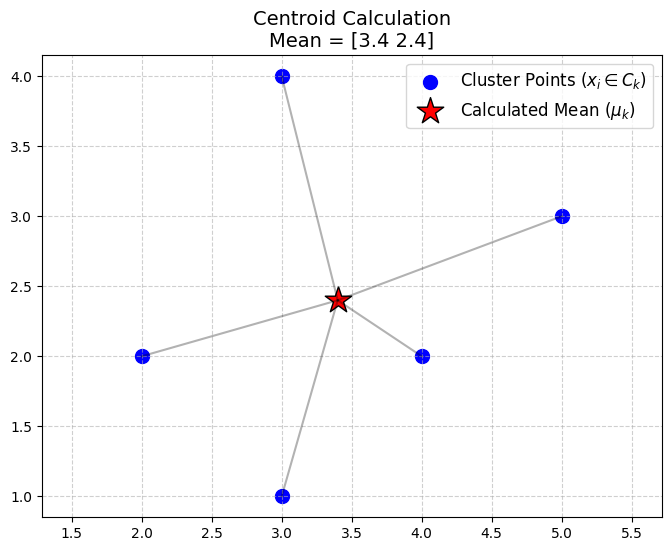

In [7]:
# Visualizing Centroid Calculation
cluster_points = np.array([[2, 2], [3, 4], [4, 2], [3, 1], [5, 3]])

# Calculate mean manually
calculated_centroid = np.mean(cluster_points, axis=0)

plt.figure(figsize=(8, 6))
plt.scatter(cluster_points[:, 0], cluster_points[:, 1], c='blue', s=100, label='Cluster Points ($x_i \in C_k$)')
plt.scatter(calculated_centroid[0], calculated_centroid[1], c='red', marker='*', s=400, edgecolor='k', label='Calculated Mean ($\mu_k$)')

for pt in cluster_points:
    plt.plot([pt[0], calculated_centroid[0]], [pt[1], calculated_centroid[1]], 'k-', alpha=0.3)

plt.title(f"Centroid Calculation\nMean = {calculated_centroid}", fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axis('equal')
plt.show()



---

## Section 6 — WHY IS THE MEAN THE BEST CENTROID?

This is a critical question: **Why do we use the *mean* to update the centroid? Why not the median or some other metric?**

We use the mean because it **minimizes the sum of squared distances** mathematically. Let's derive it!

Let the total squared distance for a single cluster be a function of the centroid $\mu$:
$$ J(\mu) = \sum_{i=1}^{n}(x_i - \mu)^2 $$

To find the minimum of this function, we take the derivative with respect to $\mu$ and set it to zero:
$$ \frac{dJ}{d\mu} = -2\sum_{i=1}^{n}(x_i - \mu) $$

Set the derivative to zero:
$$ -2\sum_{i=1}^{n}(x_i - \mu) = 0 $$
$$ \sum_{i=1}^{n}(x_i - \mu) = 0 $$
$$ \sum_{i=1}^{n}x_i - \sum_{i=1}^{n}\mu = 0 $$

Since $\sum_{i=1}^{n}\mu = n\mu$:
$$ \sum_{i=1}^{n}x_i - n\mu = 0 $$

Solving for $\mu$:
$$ \boxed{ \mu = \frac{1}{n}\sum_{i=1}^{n}x_i } $$

**Conclusion in beginner-friendly language:**
If you want to place a central point such that the total squared distance to all surrounding points is as small as possible, the optimal location is exactly their average (the mean). Any other location will result in a larger total squared distance!



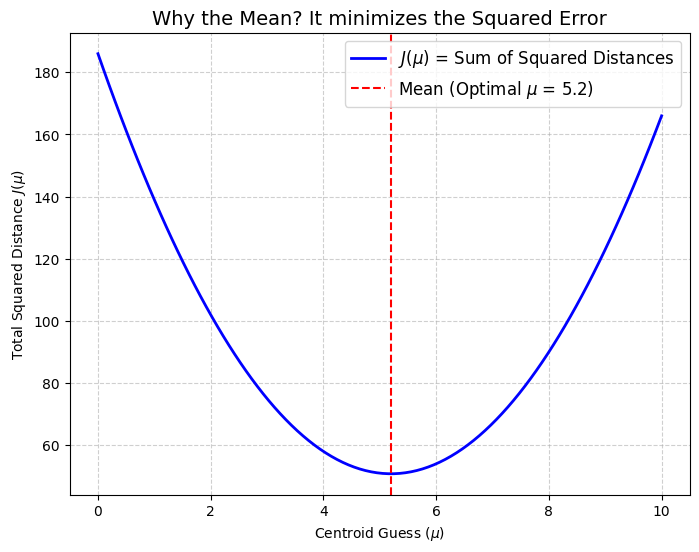

In [8]:
# Visualizing Total Squared Distance vs Centroid Position (1D)
points_1d = np.array([1, 2, 6, 8, 9])
best_mu = np.mean(points_1d)

mu_guesses = np.linspace(0, 10, 100)
J_values = [np.sum((points_1d - mu)**2) for mu in mu_guesses]

plt.figure(figsize=(8, 6))
plt.plot(mu_guesses, J_values, 'b-', linewidth=2, label='$J(\mu)$ = Sum of Squared Distances')
plt.axvline(best_mu, color='r', linestyle='--', label=f'Mean (Optimal $\mu$ = {best_mu:.1f})')

plt.title("Why the Mean? It minimizes the Squared Error", fontsize=14)
plt.xlabel("Centroid Guess ($\mu$)")
plt.ylabel("Total Squared Distance $J(\mu)$")
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



---

## Section 7 — K-Means Objective Function

Now that we know how to calculate distances and centroids, what is the ultimate mathematical goal of the K-Means algorithm?

K-Means tries to minimize the **Objective Function** (also known as Cost Function or Inertia):

$$ \boxed{ J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2 } $$

Let's break it down:
- $K$: Total number of clusters.
- $C_k$: The set of points in cluster $k$.
- $x_i$: A data point in cluster $C_k$.
- $\mu_k$: The centroid of cluster $C_k$.
- $\|x_i - \mu_k\|^2$: Squared distance from the point to its cluster's centroid.
- Outer sum $\sum_{k=1}^{K}$: Add up the values for all $K$ clusters.
- Inner sum $\sum_{x_i \in C_k}$: Add up the values for all points within a specific cluster.

**Why does this matter?** Minimizing this objective guarantees that our clusters are as compact and tight as possible.



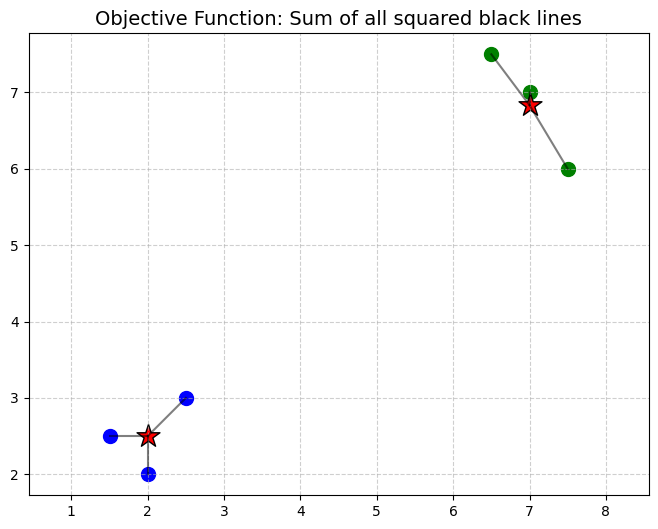

In [9]:
# Visualizing the Objective Function Concept
plt.figure(figsize=(8, 6))

c1 = np.array([[2,2], [2.5, 3], [1.5, 2.5]])
c2 = np.array([[7,7], [7.5, 6], [6.5, 7.5]])

mu1 = np.mean(c1, axis=0)
mu2 = np.mean(c2, axis=0)

plt.scatter(c1[:,0], c1[:,1], c='blue', s=100)
plt.scatter(c2[:,0], c2[:,1], c='green', s=100)
plt.scatter(mu1[0], mu1[1], c='red', marker='*', s=300, edgecolor='k')
plt.scatter(mu2[0], mu2[1], c='red', marker='*', s=300, edgecolor='k')

for pt in c1:
    plt.plot([pt[0], mu1[0]], [pt[1], mu1[1]], 'k-', alpha=0.5)
for pt in c2:
    plt.plot([pt[0], mu2[0]], [pt[1], mu2[1]], 'k-', alpha=0.5)

plt.title("Objective Function: Sum of all squared black lines", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axis('equal')
plt.show()



---

## Section 8 — WCSS / Within-Cluster Sum of Squares

A critical metric in K-Means is **WCSS** (Within-Cluster Sum of Squares). It is exactly the same as the objective function we just discussed!

$$ \boxed{ WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2 } $$

WCSS is essentially the total squared distance of every point from its corresponding cluster centroid.

Let's imagine a cluster with a centroid $\mu$ and three points, with distances $d_1, d_2, d_3$ from the centroid.
The WCSS for this cluster is:
$$ WCSS = d_1^2 + d_2^2 + d_3^2 $$

**Smaller WCSS $\rightarrow$ tighter, denser clusters.**



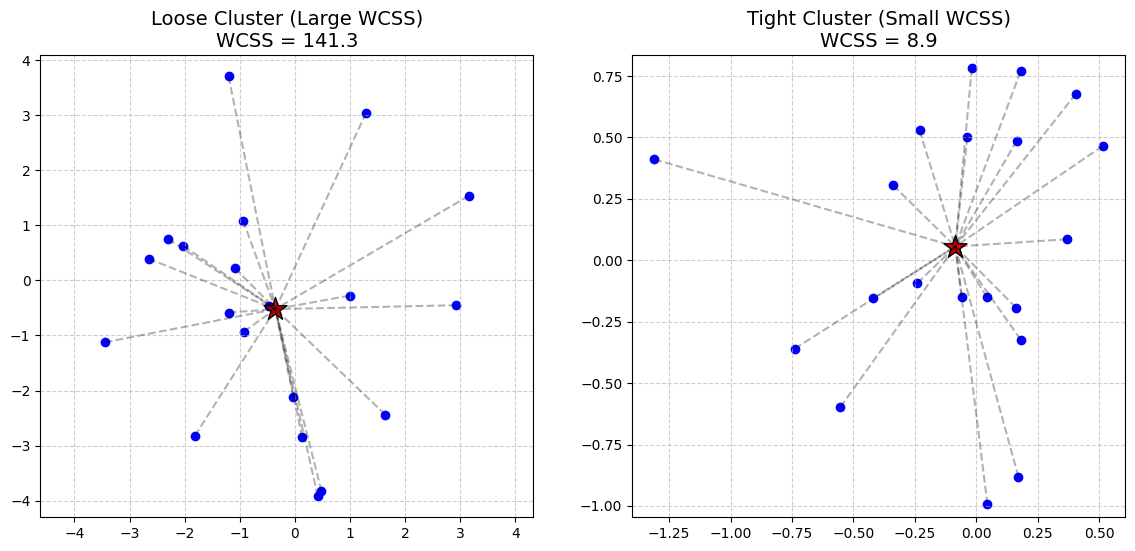

In [10]:
# Visualizing WCSS: Tighter vs Looser clusters
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Looser cluster
np.random.seed(42)
loose_pts = np.random.normal(0, 2, (20, 2))
loose_mu = np.mean(loose_pts, axis=0)
loose_wcss = np.sum(np.sum((loose_pts - loose_mu)**2, axis=1))

ax[0].scatter(loose_pts[:,0], loose_pts[:,1], c='blue')
ax[0].scatter(*loose_mu, c='red', marker='*', s=300, edgecolor='k')
for pt in loose_pts:
    ax[0].plot([pt[0], loose_mu[0]], [pt[1], loose_mu[1]], 'k--', alpha=0.3)
ax[0].set_title(f"Loose Cluster (Large WCSS)\nWCSS = {loose_wcss:.1f}", fontsize=14)
ax[0].axis('equal')
ax[0].grid(True, linestyle='--', alpha=0.6)

# Tighter cluster
tight_pts = np.random.normal(0, 0.5, (20, 2))
tight_mu = np.mean(tight_pts, axis=0)
tight_wcss = np.sum(np.sum((tight_pts - tight_mu)**2, axis=1))

ax[1].scatter(tight_pts[:,0], tight_pts[:,1], c='blue')
ax[1].scatter(*tight_mu, c='red', marker='*', s=300, edgecolor='k')
for pt in tight_pts:
    ax[1].plot([pt[0], tight_mu[0]], [pt[1], tight_mu[1]], 'k--', alpha=0.3)
ax[1].set_title(f"Tight Cluster (Small WCSS)\nWCSS = {tight_wcss:.1f}", fontsize=14)
ax[1].axis('equal')
ax[1].grid(True, linestyle='--', alpha=0.6)

plt.show()



---

## Section 9 — K-Means Algorithm Mathematically

We now have all the pieces to define the complete mathematical flow of the K-Means algorithm:

1. **Choose $K$:** The number of clusters.
2. **Initialize:** Randomly pick $K$ initial centroids $\mu_1, \mu_2, ..., \mu_K$.
3. **Assignment Step:** Assign each data point $x_i$ to the closest centroid:
$$ c_i = \arg\min_k \|x_i - \mu_k\|^2 $$
4. **Update Step:** Calculate the new centroids by taking the mean of all points assigned to them:
$$ \mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i $$
5. **Calculate WCSS:** Check the current objective cost:
$$ WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2 $$
6. **Repeat:** Repeat steps 3, 4, and 5 until convergence (i.e., when centroids no longer move or assignments do not change).



---

## Section 11 — WCSS vs Number of Clusters

How do we choose $K$?

As $K$ increases, WCSS will always decrease. Why? Because adding more centroids means data points are naturally closer to *some* centroid. If $K=n$ (number of points), WCSS becomes 0 because every point is its own centroid!

However, $K=n$ is not useful. We want to find the "sweet spot" where adding another cluster doesn't give us much better compactness. We visualize this trade-off using the **Elbow Method**:
Plotting $K \text{ vs } WCSS$ and finding the "elbow" of the curve.



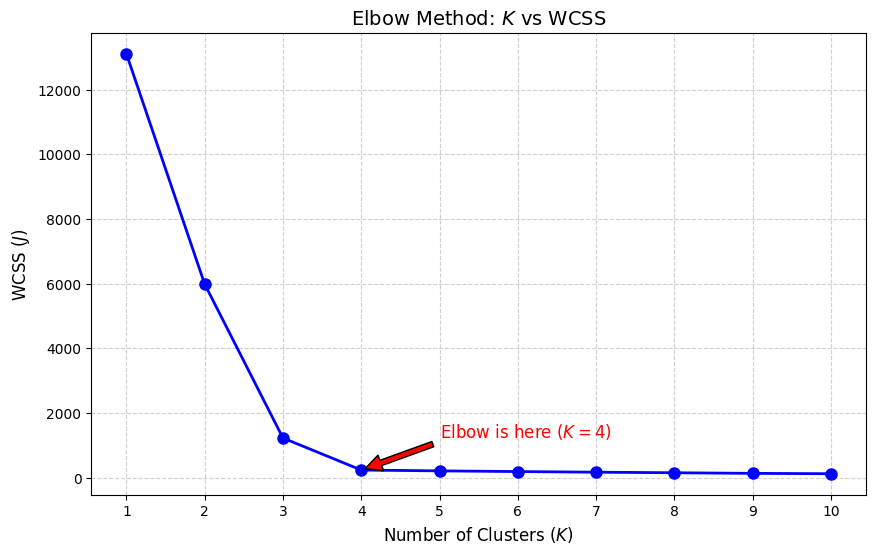

In [11]:
# Generating Elbow Curve
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Let's generate a larger dataset with exactly 4 distinct blobs
X_elbow, _ = make_blobs(n_samples=200, centers=4, cluster_std=0.8, random_state=42)

wcss_list = []
max_k = 10

for k in range(1, max_k + 1):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_elbow)
    wcss_list.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, max_k + 1), wcss_list, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title("Elbow Method: $K$ vs WCSS", fontsize=14)
plt.xlabel("Number of Clusters ($K$)", fontsize=12)
plt.ylabel("WCSS ($J$)", fontsize=12)
plt.xticks(range(1, max_k + 1))
plt.grid(True, linestyle='--', alpha=0.6)

# Annotate the elbow
plt.annotate('Elbow is here ($K=4$)', xy=(4, wcss_list[3]), xytext=(5, wcss_list[3] + 1000),
             arrowprops=dict(facecolor='red', shrink=0.05), fontsize=12, color='red')

plt.show()



---

## Section 13 — Important Mathematical Limitations

While K-Means is powerful, its mathematical foundation brings some limitations:

1. **Local Minimum:** K-Means minimizes WCSS, but it can get stuck in a "local minimum" depending on where the initial centroids are placed. It is not guaranteed to find the absolute best "global minimum".
2. **Initialization Dependency:** Because of the local minimum problem, running the algorithm with different random starts can yield different final clusters. (This is why `k-means++` or n_init initialization is commonly used in practice).
3. **Feature Scale Sensitivity:** Since Euclidean distance treats all dimensions equally, features with larger numerical ranges will dominate the distance calculation. (Data should almost always be scaled/standardized before K-Means).
4. **Spherical Clusters Only:** The Euclidean distance equation models a circle/sphere around the centroid. K-Means struggles severely with elongated or non-spherical clusters.
5. **Choosing $K$ is manual:** The algorithm cannot mathematically figure out the optimal $K$ by itself.

---



## K-Means Mathematical Cheat Sheet

| Concept | Mathematical Formula |
|:---|:---|
| **Data Point** | $x_i = (x_{i1}, x_{i2}, ..., x_{id})$ |
| **Centroid** | $\mu_k = (\mu_{k1}, \mu_{k2}, ..., \mu_{kd})$ |
| **Euclidean Distance** | $d(x,y) = \sqrt{\sum_{j=1}^{d}(x_j - y_j)^2}$ |
| **Squared Euclidean Distance** | $d^2(x,y) = \sum_{j=1}^{d}(x_j - y_j)^2$ |
| **Cluster Assignment** | $c_i = \arg\min_k \|x_i - \mu_k\|^2$ |
| **Centroid Derivation** | $\frac{dJ}{d\mu} = 0 \implies \mu = \frac{1}{n}\sum_{i} x_i$ |

| **Objective Function** | $J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$ |
| **WCSS** | $WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$ |
| **Elbow Method** | Trade-off curve: $K \rightarrow WCSS$ |

Thank you for completing this mathematical journey into K-Means Clustering!